# Credit Pre-Screening Engine — MUC02 (KLU)

**Objective:** Build a supervised classification model that predicts the bank's historical `Declined` decision and evaluate whether high-confidence declines can be safely routed away from manual review.

**Dataset:** `MUC02_Credit_PreScreening_Dataset.csv` (place this CSV in the same folder as this notebook).

**Important:** This model learns historical analyst decisions, not whether a customer actually repaid a loan. Treat results as a learning exercise, not as a production credit decision system.

## 1. CBIM Problem Canvas

- **Situation:** The bank receives around 3,000 personal-loan applications monthly and manually reviews each application.
- **Complication:** Analyst time may be spent on clear-cut declines while other applications wait for human judgement.
- **Question:** Which applications, if any, can be safely removed from manual review while keeping the share of approved customers among auto-declines at or below 5%?
- **SSOT:** The supplied CSV; `decision` represents the historical credit team's judgement, not repayment performance.
- **Success definition:** Identify a threshold meeting the 5% wrong-decline rule and quantify applications and analyst hours potentially saved.
- **Stakeholders:** Credit Policy Analyst, Head of Retail Lending, credit analysts, and loan applicants.

## 2. Import libraries and load the dataset

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    precision_score, recall_score, roc_auc_score, ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

DATA_PATH = "MUC02_Credit_PreScreening_Dataset.csv"
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (12000, 19)


,application_id,application_date,age,gender,city,city_tier,employment_type,years_in_current_job,monthly_income,existing_emi,credit_score,credit_history_months,num_active_loans,delinquencies_24m,loan_purpose,loan_amount,tenure_months,proposed_emi,decision
0,APP100001,2026-04-01,28,Male,Hyderabad,1,Salaried,4.100,"95,000.000","23,500.000",784.000,109,2,0,Home Renovation,"240,000.000",48,"6,600.000",Approved
1,APP100002,2026-04-01,36,Female,Raipur,3,Business Owner,0.600,"43,000.000","8,500.000",790.000,162,2,0,Wedding,"145,000.000",36,"5,000.000",Approved
2,APP100003,2026-04-01,35,Male,Nagpur,2,Salaried,4.400,"35,000.000","3,500.000",718.000,151,1,1,Medical,"345,000.000",36,"11,800.000",Approved
3,APP100004,2026-04-01,42,Male,Jaipur,2,Salaried,5.800,"44,500.000",0.000,NaN,0,0,0,Travel,"135,000.000",36,"4,600.000",Approved
4,APP100005,2026-04-01,34,Male,Kochi,2,Self-Employed Professional,2.100,"83,500.000","6,000.000",700.000,127,1,3,Medical,"700,000.000",24,"33,600.000",Declined


## 3. Inspect the data

In [2]:
print("Column names:")
print(df.columns.tolist())

print("\\nData types:")
display(df.dtypes.rename("dtype").to_frame())

print("\\nMissing values:")
missing_summary = df.isna().sum().sort_values(ascending=False)
display(missing_summary[missing_summary > 0].rename("missing_count").to_frame())

print("\\nDuplicate rows:", df.duplicated().sum())
print("\\nDecision counts:")
display(df["decision"].value_counts(dropna=False).to_frame("count"))

approval_rate = (df["decision"].eq("Approved").mean() * 100)
print(f"Overall approval rate: {approval_rate:.1f}%")

Column names:
['application_id', 'application_date', 'age', 'gender', 'city', 'city_tier', 'employment_type', 'years_in_current_job', 'monthly_income', 'existing_emi', 'credit_score', 'credit_history_months', 'num_active_loans', 'delinquencies_24m', 'loan_purpose', 'loan_amount', 'tenure_months', 'proposed_emi', 'decision']
\nData types:


,dtype
application_id,str
application_date,str
age,int64
gender,str
city,str
city_tier,int64
employment_type,str
years_in_current_job,float64
monthly_income,float64
existing_emi,float64


\nMissing values:


,missing_count
credit_score,1039
monthly_income,441


\nDuplicate rows: 0
\nDecision counts:


,count
decision,
Approved,6353
Declined,5647


Overall approval rate: 52.9%


## 4. Clean the data

Cleaning decisions follow the use-case reference:

1. **Missing income:** Fill with the median income within each `employment_type`. Missing income is concentrated in self-employed/business-owner groups, so retain those applications.
2. **Missing credit score:** Keep these rows. Check `credit_history_months`; blank scores with zero history represent new-to-credit (NTC) applicants. Create `is_ntc` before imputing scores.
3. **Implausibly high monthly income:** Values above ₹6,00,000 are treated as likely annual income entered in the monthly field and divided by 12.
4. Avoid dropping all rows with missing values.

In [3]:
df = df.copy()

# Convert application_date to datetime for inspection; it will not be used as a model feature.
df["application_date"] = pd.to_datetime(df["application_date"], errors="coerce")

# Create NTC flag BEFORE filling credit_score.
df["is_ntc"] = df["credit_score"].isna().astype(int)

# Verify missing scores against credit history.
blank_score_rows = df["credit_score"].isna()
print("Blank credit scores:", int(blank_score_rows.sum()))
print("Credit history months among blank-score applicants:")
display(df.loc[blank_score_rows, "credit_history_months"].value_counts(dropna=False).rename("count").to_frame())

# Fix likely annual income entered as monthly income.
high_income_mask = df["monthly_income"] > 600_000
print("Income values above ₹6,00,000 before correction:", int(high_income_mask.sum()))
if high_income_mask.any():
    display(df.loc[high_income_mask, ["application_id", "employment_type", "monthly_income"]].head(20))
df.loc[high_income_mask, "monthly_income"] = df.loc[high_income_mask, "monthly_income"] / 12

# Fill income by employment-type median; fallback to overall median if a group median is unavailable.
income_medians = df.groupby("employment_type")["monthly_income"].transform("median")
df["monthly_income"] = df["monthly_income"].fillna(income_medians)
df["monthly_income"] = df["monthly_income"].fillna(df["monthly_income"].median())

print("Missing monthly_income after cleaning:", int(df["monthly_income"].isna().sum()))
print("Missing credit_score retained for modelling:", int(df["credit_score"].isna().sum()))
print("NTC applicants flagged:", int(df["is_ntc"].sum()))

Blank credit scores: 1039
Credit history months among blank-score applicants:


,count
credit_history_months,
0,1039


Income values above ₹6,00,000 before correction: 12


,application_id,employment_type,monthly_income
300,APP100301,Salaried,"1,254,000.000"
589,APP100590,Salaried,"1,068,000.000"
1467,APP101468,Salaried,"1,656,000.000"
1848,APP101849,Salaried,"984,000.000"
2488,APP102489,Salaried,"972,000.000"
2493,APP102494,Salaried,"1,212,000.000"
4010,APP104011,Salaried,"900,000.000"
4898,APP104899,Salaried,"870,000.000"
7426,APP107427,Salaried,"690,000.000"
8381,APP108382,Salaried,"618,000.000"


Missing monthly_income after cleaning: 0
Missing credit_score retained for modelling: 1039
NTC applicants flagged: 1039


## 5. Explore the target and key variables

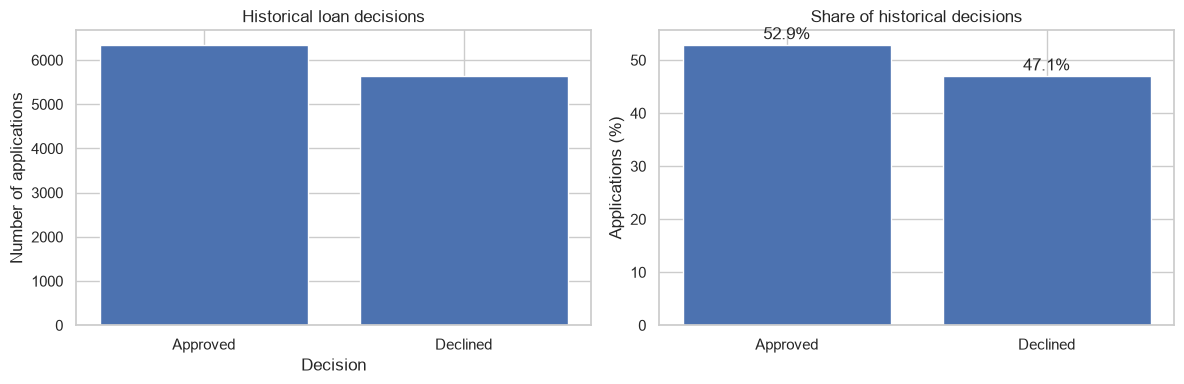

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
decision_counts = df["decision"].value_counts().reindex(["Approved", "Declined"], fill_value=0)
axes[0].bar(decision_counts.index, decision_counts.values)
axes[0].set_title("Historical loan decisions")
axes[0].set_xlabel("Decision")
axes[0].set_ylabel("Number of applications")

decision_pct = df["decision"].value_counts(normalize=True).reindex(["Approved", "Declined"]) * 100
axes[1].bar(decision_pct.index, decision_pct.values)
axes[1].set_title("Share of historical decisions")
axes[1].set_ylabel("Applications (%)")
for i, v in enumerate(decision_pct.values):
    axes[1].text(i, v + 1, f"{v:.1f}%", ha="center")
plt.tight_layout()
plt.show()

,approval_rate_pct
credit_score_band,
Below 600,2.033
600–649,3.215
650–699,32.503
700–749,54.368
750–799,77.197
800+,85.185
No score,53.898


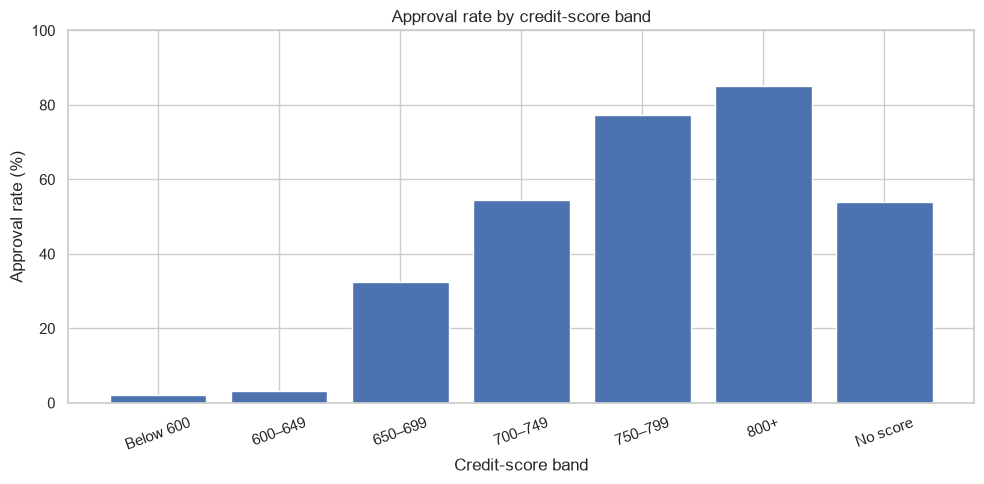

In [5]:
# Approval rate by credit-score band, including applicants with no score.
score_bins = [-np.inf, 599, 649, 699, 749, 799, np.inf]
score_labels = ["Below 600", "600–649", "650–699", "700–749", "750–799", "800+"]
df["credit_score_band"] = pd.cut(df["credit_score"], bins=score_bins, labels=score_labels)
df["credit_score_band"] = df["credit_score_band"].cat.add_categories(["No score"]).fillna("No score")

score_approval = (df.assign(approved=df["decision"].eq("Approved").astype(int))
                    .groupby("credit_score_band", observed=False)["approved"].mean() * 100)
display(score_approval.rename("approval_rate_pct").to_frame())

plt.figure(figsize=(10, 5))
plt.bar([str(x) for x in score_approval.index], score_approval.values)
plt.title("Approval rate by credit-score band")
plt.xlabel("Credit-score band")
plt.ylabel("Approval rate (%)")
plt.xticks(rotation=20)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

,approval_rate_pct
employment_type,
Salaried,58.368
Business Owner,51.172
Self-Employed Professional,50.560
Gig / Contract,34.938


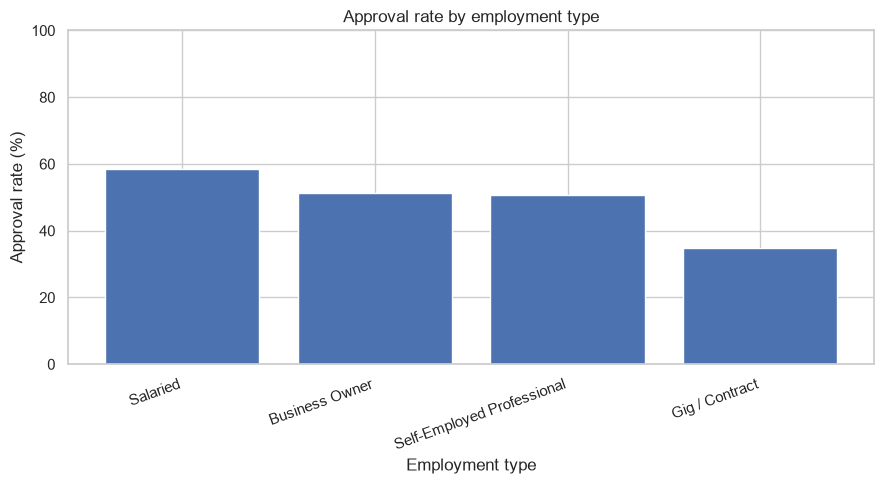

In [6]:
employment_approval = (df.assign(approved=df["decision"].eq("Approved").astype(int))
                         .groupby("employment_type")["approved"].mean().sort_values(ascending=False) * 100)
display(employment_approval.rename("approval_rate_pct").to_frame())

plt.figure(figsize=(9, 5))
plt.bar([str(x) for x in employment_approval.index], employment_approval.values)
plt.title("Approval rate by employment type")
plt.xlabel("Employment type")
plt.ylabel("Approval rate (%)")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

## 6. Engineer affordability features: FOIR and loan-to-income

,approval_rate_pct
foir_band,
Below 30%,65.436
30–40%,59.007
40–50%,47.424
50–55%,31.660
Above 55%,15.546


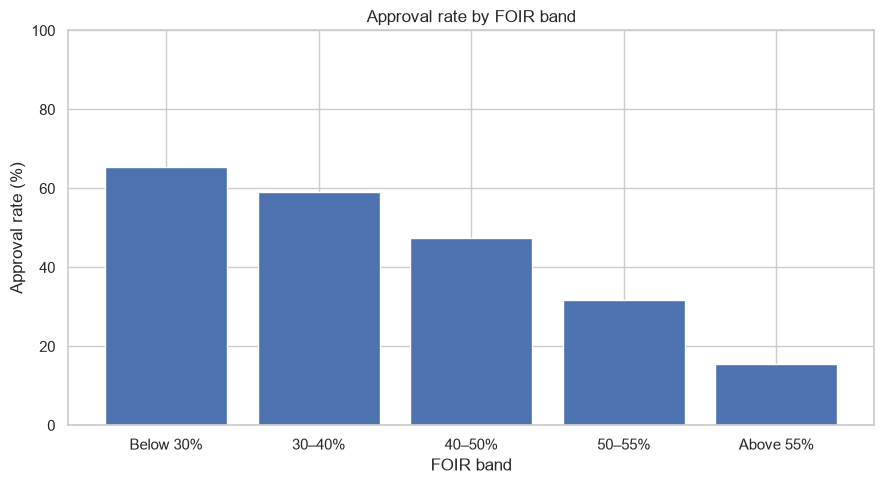

FOIR is the share of monthly income consumed by existing and proposed EMIs.
Inspect the chart to identify where approval rates fall sharply; historical association is not proof of causation.


In [7]:
# Protect against division by zero or invalid income values.
safe_income = df["monthly_income"].replace(0, np.nan)
df["foir"] = (df["existing_emi"] + df["proposed_emi"]) / safe_income
df["loan_to_income"] = df["loan_amount"] / (safe_income * 12)

# FOIR approval rates using the requested bands.
foir_bins = [-np.inf, 0.30, 0.40, 0.50, 0.55, np.inf]
foir_labels = ["Below 30%", "30–40%", "40–50%", "50–55%", "Above 55%"]
df["foir_band"] = pd.cut(df["foir"], bins=foir_bins, labels=foir_labels)

foir_approval = (df.assign(approved=df["decision"].eq("Approved").astype(int))
                   .groupby("foir_band", observed=False)["approved"].mean() * 100)
display(foir_approval.rename("approval_rate_pct").to_frame())

plt.figure(figsize=(9, 5))
plt.bar([str(x) for x in foir_approval.index], foir_approval.values)
plt.title("Approval rate by FOIR band")
plt.xlabel("FOIR band")
plt.ylabel("Approval rate (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

print("FOIR is the share of monthly income consumed by existing and proposed EMIs.")
print("Inspect the chart to identify where approval rates fall sharply; historical association is not proof of causation.")

## 7. Prepare the classification target and features

The assignment specifies **Declined = 1** and **Approved = 0**. The model therefore estimates the probability of a historical decline.

Excluded from features: `application_id`, `application_date`, `city`, `gender`, `decision`, and the exploration-only band columns. `gender` is excluded from training but retained for the separate fairness check. Numeric features are median-imputed and scaled; categorical features are mode-imputed and one-hot encoded.

In [8]:
df_model = df.copy()
df_model = df_model[df_model["decision"].isin(["Approved", "Declined"])].copy()
df_model["target_declined"] = df_model["decision"].map({"Approved": 0, "Declined": 1}).astype(int)

numeric_features = [
    "credit_score", "is_ntc", "foir", "loan_to_income",
    "delinquencies_24m", "num_active_loans", "years_in_current_job",
    "age", "tenure_months", "city_tier"
]
categorical_features = ["employment_type", "loan_purpose"]
feature_columns = numeric_features + categorical_features

X = df_model[feature_columns]
y = df_model["target_declined"]

X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X, y, df_model.index,
    test_size=0.20,
    stratify=y,
    random_state=42
)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000, class_weight=None, random_state=42))
])

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Training target proportions:")
display(y_train.value_counts(normalize=True).rename("proportion").to_frame())

Training rows: 9600
Test rows: 2400
Training target proportions:


,proportion
target_declined,
0,0.529
1,0.471


## 8. Train Logistic Regression and evaluate at the default 0.50 threshold

Accuracy: 0.791
Precision (Declined class): 0.791
Recall (Declined class): 0.755
ROC-AUC: 0.867
\nClassification report:
              precision    recall  f1-score   support

    Approved       0.79      0.82      0.81      1271
    Declined       0.79      0.75      0.77      1129

    accuracy                           0.79      2400
   macro avg       0.79      0.79      0.79      2400
weighted avg       0.79      0.79      0.79      2400



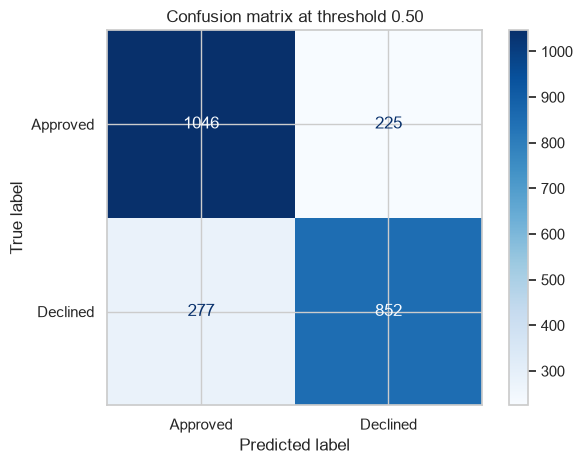

False positives for the Declined class: 225
Business interpretation: 225 applicants historically Approved would be predicted Declined at threshold 0.50.
False negatives for the Declined class: 277 historically Declined applicants would be predicted Approved.


In [9]:
model.fit(X_train, y_train)

y_prob = model.predict_proba(X_test)[:, 1]
y_pred_05 = (y_prob >= 0.50).astype(int)

accuracy = accuracy_score(y_test, y_pred_05)
precision_declined = precision_score(y_test, y_pred_05, pos_label=1, zero_division=0)
recall_declined = recall_score(y_test, y_pred_05, pos_label=1, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)

print(f"Accuracy: {accuracy:.3f}")
print(f"Precision (Declined class): {precision_declined:.3f}")
print(f"Recall (Declined class): {recall_declined:.3f}")
print(f"ROC-AUC: {roc_auc:.3f}")
print("\\nClassification report:")
print(classification_report(y_test, y_pred_05, target_names=["Approved", "Declined"], zero_division=0))

cm = confusion_matrix(y_test, y_pred_05, labels=[0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Approved", "Declined"])
disp.plot(values_format="d", cmap="Blues")
plt.title("Confusion matrix at threshold 0.50")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"False positives for the Declined class: {fp}")
print(f"Business interpretation: {fp} applicants historically Approved would be predicted Declined at threshold 0.50.")
print(f"False negatives for the Declined class: {fn} historically Declined applicants would be predicted Approved.")

## 9. Interpret the five largest Logistic Regression coefficients

,feature,coefficient,direction
2,foir,1.220,Pushes toward Declined
0,credit_score,-1.010,Pushes toward Approved
4,delinquencies_24m,0.979,Pushes toward Declined
11,employment_type_Gig / Contract,0.619,Pushes toward Declined
12,employment_type_Salaried,-0.444,Pushes toward Approved


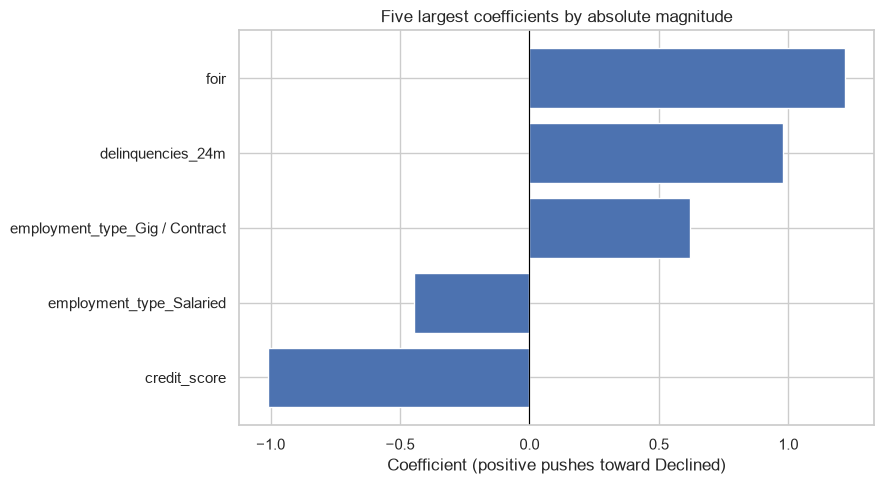

Coefficient sizes are on the transformed feature scale; categorical features are one-hot encoded.
These coefficients describe associations learned from historical decisions, not causal effects.


In [10]:
# Recover feature names after preprocessing.
preprocessor_fitted = model.named_steps["preprocessor"]
ohe = preprocessor_fitted.named_transformers_["cat"].named_steps["onehot"]
categorical_names = list(ohe.get_feature_names_out(categorical_features))
all_feature_names = numeric_features + categorical_names
coefficients = model.named_steps["classifier"].coef_[0]

coef_table = pd.DataFrame({
    "feature": all_feature_names,
    "coefficient": coefficients
})
coef_table["direction"] = np.where(coef_table["coefficient"] > 0, "Pushes toward Declined", "Pushes toward Approved")
coef_table["abs_coefficient"] = coef_table["coefficient"].abs()
top5 = coef_table.sort_values("abs_coefficient", ascending=False).head(5)
display(top5[["feature", "coefficient", "direction"]])

plot_coefs = top5.sort_values("coefficient")
plt.figure(figsize=(9, 5))
plt.barh(plot_coefs["feature"], plot_coefs["coefficient"])
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Five largest coefficients by absolute magnitude")
plt.xlabel("Coefficient (positive pushes toward Declined)")
plt.tight_layout()
plt.show()

print("Coefficient sizes are on the transformed feature scale; categorical features are one-hot encoded.")
print("These coefficients describe associations learned from historical decisions, not causal effects.")

## 10. Choose a high-confidence auto-decline threshold

The bank's rule is: **no more than 5% of auto-declined applications may have actually been Approved** by the historical credit team.

For each threshold, auto-decline if predicted probability of `Declined` is greater than or equal to the threshold. The “wrongly declined %” is the share of these auto-declined applications whose true label is Approved (class 0).

In [11]:
thresholds = [0.50, 0.60, 0.70, 0.80, 0.85, 0.90, 0.95]
threshold_rows = []

y_test_array = np.asarray(y_test)
for threshold in thresholds:
    auto_mask = y_prob >= threshold
    auto_count = int(auto_mask.sum())
    auto_pct = 100 * auto_count / len(y_test_array)
    wrong_count = int(((y_test_array == 0) & auto_mask).sum())
    wrong_pct = 100 * wrong_count / auto_count if auto_count else np.nan
    actual_declines_caught = int(((y_test_array == 1) & auto_mask).sum())
    decline_recall = 100 * actual_declines_caught / int((y_test_array == 1).sum())
    threshold_rows.append({
        "threshold": threshold,
        "auto_declined_pct": auto_pct,
        "wrongly_declined_pct_of_auto_declines": wrong_pct,
        "declines_caught_pct": decline_recall,
        "auto_declined_test_count": auto_count
    })

threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table.round(2))

eligible = threshold_table[
    threshold_table["wrongly_declined_pct_of_auto_declines"].notna()
    & (threshold_table["wrongly_declined_pct_of_auto_declines"] <= 5.0)
]
if not eligible.empty:
    # Choose the eligible threshold with the highest auto-decline share.
    selected_row = eligible.sort_values("auto_declined_pct", ascending=False).iloc[0]
    selected_threshold = float(selected_row["threshold"])
    print(f"Selected threshold from the specified candidates: {selected_threshold:.2f}")
    print(f"Auto-declined: {selected_row['auto_declined_pct']:.1f}%")
    print(f"Wrongly declined among auto-declines: {selected_row['wrongly_declined_pct_of_auto_declines']:.1f}%")
else:
    selected_threshold = None
    print("None of the listed thresholds meets the 5% rule on this test set. Do not auto-decline; investigate or evaluate more conservative thresholds.")

,threshold,auto_declined_pct,wrongly_declined_pct_of_auto_declines,declines_caught_pct,auto_declined_test_count
0,0.500,44.880,20.890,75.470,1077
1,0.600,37.620,16.830,66.520,903
2,0.700,30.750,12.060,57.480,738
3,0.800,23.460,7.100,46.320,563
4,0.850,19.670,5.930,39.330,472
5,0.900,15.210,4.660,30.820,365
6,0.950,10.000,2.080,20.810,240


Selected threshold from the specified candidates: 0.90
Auto-declined: 15.2%
Wrongly declined among auto-declines: 4.7%


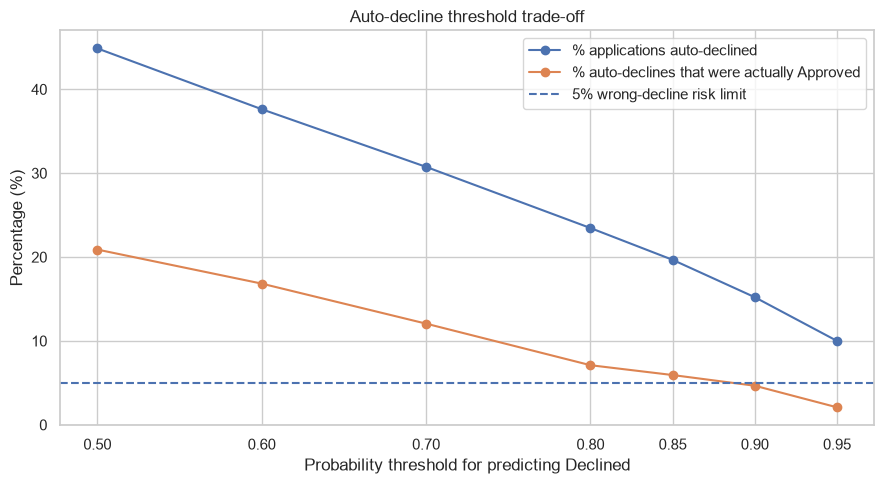

In [12]:
fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.plot(threshold_table["threshold"], threshold_table["auto_declined_pct"],
         marker="o", label="% applications auto-declined")
ax1.plot(threshold_table["threshold"], threshold_table["wrongly_declined_pct_of_auto_declines"],
         marker="o", label="% auto-declines that were actually Approved")
ax1.axhline(5, linestyle="--", label="5% wrong-decline risk limit")
ax1.set_xlabel("Probability threshold for predicting Declined")
ax1.set_ylabel("Percentage (%)")
ax1.set_title("Auto-decline threshold trade-off")
ax1.set_xticks(thresholds)
ax1.legend()
plt.tight_layout()
plt.show()

## 11. Translate the threshold into monthly analyst hours

In [13]:
MONTHLY_APPLICATIONS = 3000
MINUTES_PER_REVIEW = 25

if selected_threshold is not None:
    selected = threshold_table.loc[threshold_table["threshold"].eq(selected_threshold)].iloc[0]
    monthly_auto_declines = MONTHLY_APPLICATIONS * selected["auto_declined_pct"] / 100
    monthly_hours_saved = monthly_auto_declines * MINUTES_PER_REVIEW / 60
    print(f"Threshold: {selected_threshold:.2f}")
    print(f"Estimated applications auto-declined per month: {monthly_auto_declines:.0f} of {MONTHLY_APPLICATIONS}")
    print(f"Estimated analyst hours potentially freed per month: {monthly_hours_saved:.1f}")
    print(f"Wrongly declined share of auto-declines: {selected['wrongly_declined_pct_of_auto_declines']:.2f}%")
    print("This is a theoretical workload estimate; it assumes each auto-declined application otherwise takes a full 25-minute review.")
else:
    print("No threshold met the risk rule; monthly auto-decline savings are not recommended.")

Threshold: 0.90
Estimated applications auto-declined per month: 456 of 3000
Estimated analyst hours potentially freed per month: 190.1
Wrongly declined share of auto-declines: 4.66%
This is a theoretical workload estimate; it assumes each auto-declined application otherwise takes a full 25-minute review.


## 12. Fairness check by gender

Gender is not a model feature. However, income and employment type may act as proxies, so compare historical outcomes and model auto-decline rates by gender. This analysis is a monitoring check, not proof that the model is fair.

In [14]:
fairness_df = df_model.loc[idx_test, ["gender", "employment_type", "monthly_income", "decision"]].copy()
fairness_df["y_true"] = y_test.values
fairness_df["decline_probability"] = y_prob
fairness_df["predicted_declined_05"] = y_pred_05

print("Historical approval rate by gender:")
hist_gender = (df_model.assign(approved=df_model["decision"].eq("Approved").astype(int))
               .groupby("gender")["approved"].mean().mul(100).rename("approval_rate_pct"))
display(hist_gender.to_frame())

print("Historical approval rate by gender within employment type:")
gender_employment = (df_model.assign(approved=df_model["decision"].eq("Approved").astype(int))
                     .pivot_table(index="employment_type", columns="gender", values="approved", aggfunc="mean") * 100)
display(gender_employment.round(2))

print("Median monthly income by gender:")
display(df_model.groupby("gender")["monthly_income"].median().rename("median_monthly_income_INR").to_frame())

print("Share of Gig / Contract workers by gender:")
gig_share = df_model.assign(is_gig=df_model["employment_type"].eq("Gig / Contract").astype(int)).groupby("gender")["is_gig"].mean().mul(100)
display(gig_share.rename("gig_contract_share_pct").to_frame())

if selected_threshold is not None:
    fairness_df["auto_declined_selected"] = (fairness_df["decline_probability"] >= selected_threshold).astype(int)
    auto_decline_gender = fairness_df.groupby("gender")["auto_declined_selected"].mean().mul(100)
    print(f"Model auto-decline rate by gender at threshold {selected_threshold:.2f}:")
    display(auto_decline_gender.rename("auto_decline_rate_pct").to_frame())
else:
    print("No selected threshold was available for the 5% rule.")

Historical approval rate by gender:


,approval_rate_pct
gender,
Female,50.435
Male,54.101


Historical approval rate by gender within employment type:


gender,Female,Male
employment_type,,
Business Owner,51.620,51.050
Gig / Contract,34.650,35.180
Salaried,56.790,59.060
Self-Employed Professional,47.630,51.970


Median monthly income by gender:


,median_monthly_income_INR
gender,
Female,"45,000.000"
Male,"55,000.000"


Share of Gig / Contract workers by gender:


,gig_contract_share_pct
gender,
Female,21.370
Male,11.639


Model auto-decline rate by gender at threshold 0.90:


,auto_decline_rate_pct
gender,
Female,15.600
Male,15.030


## 13. Final decision helper for a new application

This function uses the trained pipeline and selected threshold. It returns the model's estimated probability of historical decline and a **routing recommendation**:
- **Auto-decline candidate:** probability meets the selected threshold, but only if a threshold passed the 5% test-set rule.
- **Manual review:** otherwise.

For safety, NTC applications (no credit score) are always sent to manual review because the reference results show weaker model performance for this group. This is a conservative business guardrail, not a claim that these applicants should be declined.

In [15]:
def recommend_routing(application: dict) -> dict:
    """Return a pre-screening routing suggestion for one application.

    Required keys are the model features listed below. Missing numeric/categorical
    values are handled by the preprocessing pipeline, except credit_score missing
    sets is_ntc=1. This is an educational demo, not a lending decision.
    """
    if selected_threshold is None:
        raise RuntimeError("No threshold met the 5% wrong-decline rule; manual review is recommended for all applications.")

    row = pd.DataFrame([application]).copy()
    required = numeric_features + categorical_features
    missing_keys = [col for col in required if col not in row.columns]
    if missing_keys:
        raise ValueError(f"Missing required feature keys: {missing_keys}")

    # If credit_score is absent, preserve NTC status before model imputation.
    if pd.isna(row.loc[0, "credit_score"]):
        row.loc[0, "is_ntc"] = 1

    probability_declined = float(model.predict_proba(row[feature_columns])[:, 1][0])
    is_ntc = int(row.loc[0, "is_ntc"])

    if is_ntc == 1:
        routing = "Manual review (new-to-credit guardrail)"
    elif probability_declined >= selected_threshold:
        routing = "Auto-decline candidate — human oversight and policy approval required"
    else:
        routing = "Manual review"

    return {
        "probability_of_historical_decline": round(probability_declined, 4),
        "selected_threshold": selected_threshold,
        "routing_recommendation": routing
    }

# Example: take one held-out test application and demonstrate the routing helper.
example_application = X_test.iloc[0].to_dict()
display(pd.DataFrame([example_application]))
print(recommend_routing(example_application))

,credit_score,is_ntc,foir,loan_to_income,delinquencies_24m,num_active_loans,years_in_current_job,age,tenure_months,city_tier,employment_type,loan_purpose
0,803.000,0,0.537,0.499,0,0,8.800,30,12,3,Salaried,Home Renovation


{'probability_of_historical_decline': 0.1463, 'selected_threshold': 0.9, 'routing_recommendation': 'Manual review'}


## 14. Credit Policy Briefing (fill in after reviewing your actual outputs)

Use your actual notebook results to complete this short briefing:

> I recommend using a threshold of **[threshold]** only for high-confidence decline candidates. On the test data, this would route approximately **[percentage]%** of applications away from standard manual review, equivalent to **[applications] applications** and **[hours] analyst hours** per month, while **[wrong-decline percentage]%** of those candidates were historically approved. The strongest factors associated with historical decline were **[driver 1 with result]** and **[driver 2 with result]**. New-to-credit applicants should continue to receive human review because **[evidence]**. Although gender was excluded from training, income and employment type may act as proxies, so outcomes should be monitored by gender. Before any production use, validate the model against actual repayment outcomes and conduct policy, fairness, and compliance review.

### Final checklist
- [ ] Notebook runs from top to bottom after restarting the kernel.
- [ ] CSV is in the same folder as this notebook.
- [ ] Cleaning choices and their reasons are documented.
- [ ] NTC applicants were retained.
- [ ] `gender`, `city`, IDs, dates, and `decision` were excluded from model features.
- [ ] The chosen threshold is supported by the observed 5% risk test.
- [ ] Business impact and fairness are interpreted using actual outputs.